# 04 · Inspect an observation record

Read the six NumPy files and plume quantification summary for one observation.  
Inspect array properties, derive a valid-pixel mask, and compare the imagery from all four sensors.

### 1. Load the catalog and select an observation

Choose a plume observation by its original catalog index.  
Change `record_index` to inspect another observation; paths are resolved relative to `DATA_ROOT`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebook":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

from mshmm.catalog import load_catalog
from mshmm.record import load_record, describe_arrays
from mshmm.plotting import plot_record

DATA_ROOT = REPO_ROOT.parent  # Change this to your data root.
catalog = load_catalog(DATA_ROOT)
record_index = catalog.loc[catalog["is_plume"]].index[42]
record = catalog.loc[record_index]
display(record.to_frame("value"))

,value
belonging,Mexico-Nuevo_Leon
name,Simeprodeso
lon,-100.3
lat,25.87
type,waste
sensor,EMIT
time,2023-09-24 20:57:57+00:00
path,Batch0\data\Hyper_TROPOMI_landfill\Mexico\Nuev...
batch,0
is_plume,True


### 2. Read arrays and inspect their properties

`load_record` returns an array dictionary and a quantification dictionary (`None` for non-plume records).  
The six stored arrays are `RGB`, `1650`, `1730`, `CH4`, `plume`, and `plume_mask`. The derived `valid_mask` is added in memory; it is not a seventh file.

`RGB` has shape `(3, 512, 512)`; the other arrays and `valid_mask` have shape `(512, 512)`.  
Stored dtypes and missing values are preserved. In particular, GF5 single-band arrays are stored as float32 with integer-valued samples; conversion to uint16 can be performed when preparing training inputs.

The table reports finite minima and maxima, nonfinite counts, and occurrences of the `-9999` sentinel.  
Finite ranges include sentinel values so the stored values remain visible.

In [2]:
arrays, summary = load_record(DATA_ROOT, record)
display(describe_arrays(arrays))

,shape,dtype,min,max,nonfinite,sentinel_-9999
array,,,,,,
RGB,"(3, 512, 512)",float32,1634.0,21320.0,107010,0
1650,"(512, 512)",uint16,0,4023,0,0
1730,"(512, 512)",uint16,0,2774,0,0
CH4,"(512, 512)",float32,0.0,38534.988281,0,0
plume,"(512, 512)",float32,0.414671,1578.883179,260450,0
plume_mask,"(512, 512)",uint8,0,1,0,0
valid_mask,"(512, 512)",bool,False,True,0,0


### 3. Generate valid mask

`valid_mask` is a boolean array indicating pixels where **all three RGB channels and CH4** are finite and not equal to `-9999` within an absolute tolerance of `1e-6`.  
`plume_mask` identifies annotated plume pixels; `valid_mask` identifies pixels available for computation.  
Use `valid_mask` to select pixels when computing segmentation losses or metrics. A non-plume pixel can still be a valid training pixel.

In [3]:
# RGB is stored channel-first; move channels last for the validity calculation.
rgb = np.moveaxis(arrays["RGB"], 0, -1)
ch4 = arrays["CH4"]

rgb_valid = (
    np.isfinite(rgb).all(axis=2)
    & ~np.isclose(rgb, -9999, rtol=0, atol=1e-6).any(axis=2)
)
ch4_valid = (
    np.isfinite(ch4)
    & ~np.isclose(ch4, -9999, rtol=0, atol=1e-6)
)
valid = rgb_valid & ch4_valid

print(f"Valid pixels: {valid.sum():,} / {valid.size:,} ({valid.mean():.1%})")
print("Matches the reader:", np.array_equal(valid, arrays["valid_mask"]))
print("Valid annotated plume pixels:", np.count_nonzero(valid & (arrays["plume_mask"] == 1)))

Valid pixels: 226,474 / 262,144 (86.4%)
Matches the reader: True
Valid annotated plume pixels: 997


### 4. Temporary RGB correction

**BEGIN TEMPORARY FIX: MSHMM v0.1 EMIT RGB**

In dataset v0.1, EMIT RGB arrays under `Batch0/output` require multiplication by `1000`.  
`load_record` applies this correction once during loading, preserving sentinel values. It does not modify files on disk or affect other sensors or EMIT records under other directories.

The matching block in `src/mshmm/record.py` is marked with the same identifier.  
Remove that source block and this notebook section once the corrected dataset replaces v0.1. Do not apply this multiplication again to the returned arrays.

**END TEMPORARY FIX: MSHMM v0.1 EMIT RGB**

In [4]:
temporary_example = catalog.loc[
    (catalog["sensor"] == "EMIT")
    & catalog["path"].str.replace("\\", "/", regex=False).str.startswith("Batch0/output/")
].iloc[0]
corrected_arrays, _ = load_record(DATA_ROOT, temporary_example)

print("Correction example index:", temporary_example.name)
print("Returned RGB range:", np.nanmin(corrected_arrays["RGB"]), np.nanmax(corrected_arrays["RGB"]))

Correction example index: 123
Returned RGB range: 971.071 15151.564


### 5. Visualize the record

RGB uses a per-channel 2–98% percentile stretch for display only. Missing RGB pixels are shown in black; nonfinite and sentinel values in single-band panels are hidden.  
The CH4 and filtered plume panels use independent color scales. The two mask panels use a fixed 0–1 scale.

`plume.npy` is a FFT filtered product created during annotation and is shown here for inspection only.  
Training inputs and calculations use `CH4.npy` and `plume_mask.npy`, with `valid_mask` defining the eligible pixels.

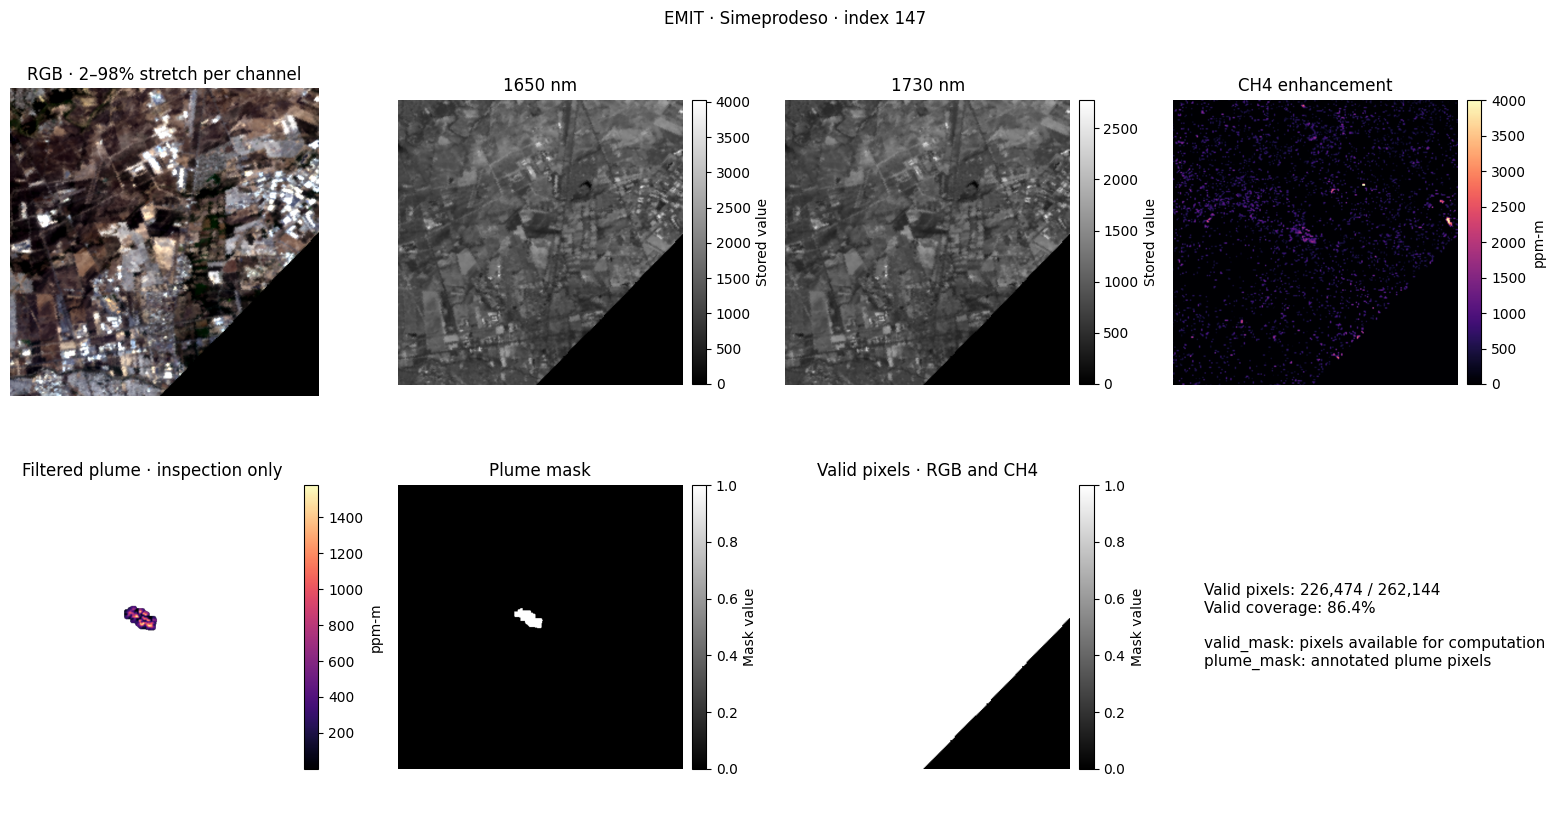

In [5]:
fig, axes = plot_record(arrays)
fig.suptitle(f"{record['sensor']} · {record['name']} · index {record.name}", y=1.02)
plt.show()

### 6. Read plume quantification

For plume observations, `sum.json` contains flux, uncertainty, Integrated Mass Enhancement, segment lengths, and meteorological information.  
The table below shows the summary together with units. `major_axis_length` contains a list of segment lengths.

Catalog fields `Q`, `Q_err`, `IME`, `length`, `wind`, and `wind_direction` correspond to `quantification`, `quantification_err`, `IME_kg`, `major_axis_length`, `wind_speed`, and `wind_direction`.     
`wind_direction` is recorded in deg, and the outward direction is recorded clockwise from due north, not the inward direction.

In [6]:
summary_units = {
    "sensor": "—", "data_time": "UTC",
    "quantification": "kg/h", "quantification_err": "kg/h",
    "IME_kg": "kg", "major_axis_length": "m",
    "wind_speed": "m/s", "wind_direction": "°",
    "temperature": "K", "pressure": "Pa",
}
if summary is not None:
    summary_table = pd.Series(summary, dtype=object).to_frame("value")
    summary_table["unit"] = pd.Series(summary_units)
    display(summary_table)
else:
    print("No quantification summary for this non-plume observation.")

,value,unit
sensor,EMIT,—
data_time,20230924T205757,UTC
quantification,1430.19,kg/h
quantification_err,493.21,kg/h
IME_kg,324.33,kg
major_axis_length,[1704.22],m
wind_speed,3.15,m/s
wind_direction,-52.41,°
temperature,310.1,K
pressure,94003.6,Pa
